# 01. EDA

Day 1에서 EDA로 세운 설계 결정은 다섯 가지였다.

1. 학습 데이터에 단수명 셀이 거의 없다 → **회귀**
2. Knee는 수명 후반에 나타난다 → 입력은 **100회차까지의 관측값만**
3. ΔQ 로그분산이 세 배치에서 가장 일관된다 → **1순위 피처**
4. 충전 전류와 첫 C-rate는 같은 정보다 → **둘 중 하나만 후보**
5. 배치 간 수명 분포·실험 절차가 다르다 → **모델 선택은 Batch 1 CV로만, Batch 2·3 성능은 마지막에 한 번 평가** (Batch 2·3은 EDA에서 피처 상관이 배치 간에 유지되는지 보는 데만 참고)

이 노트북은 Day 2 파이프라인(`src/preprocess.py`)이 원본에서 다시 추출한 값으로 위 가정이 그대로 성립하는지 확인하고, 과제가 추가로 짚은 **배치 간 Qdlin 비교 문제**를 점검한다.

In [1]:
import sys; sys.path.insert(0, "..")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import spearmanr
from src.features import load
pd.set_option("display.precision", 3)
COLORS = {"Batch 1": "#1A56DB", "Batch 2": "#EA7A1A", "Batch 3": "#8B5CF6"}
df = load()  # 수명 라벨이 있는 셀만
raw = pd.read_csv("../data/processed/cells.csv")
print(raw.groupby("batch").agg(파일_셀=("cell", "size"), 수명_있음=("life", "count")))
print("\n제외 셀:", raw.loc[raw.life.isna(), ["cell", "policy"]].to_string(index=False))

         파일_셀  수명_있음
batch               
Batch 1    46     46
Batch 2    47     39
Batch 3    46     44

제외 셀: cell                      policy
2-23      VarCharge-2C-100cycles
2-24      VarCharge-4C-100cycles
2-36      VarCharge-6C-100cycles
2-37      VarCharge-8C-100cycles
2-38    3.6C(80%)-3.6C(SLOWCYCLE
2-39    4.8C(80%)-4.8C(SLOWCYCLE
2-40       3.6C(9%)-5C(SLOWCYCLE
2-41      5.2C(58%)-4C(SLOWCYCLE
3-24 4.8C(80%)-4.8C-newstructure
3-33 4.8C(80%)-4.8C-newstructure


**분석 대상 129셀(46 / 39 / 44).** 제외한 10셀은 모두 `cycle_life`가 비어 있다. Batch 2의 8셀은 VarCharge·SLOWCYCLE로 다른 실험이고, Batch 3의 2셀은 기록이 없다. 극단 수명을 이유로 제거한 셀은 없다. 수명이 극단적인 셀도 모델이 예측해야 할 대상이기 때문이다.

## 1. Cycle Life 분포

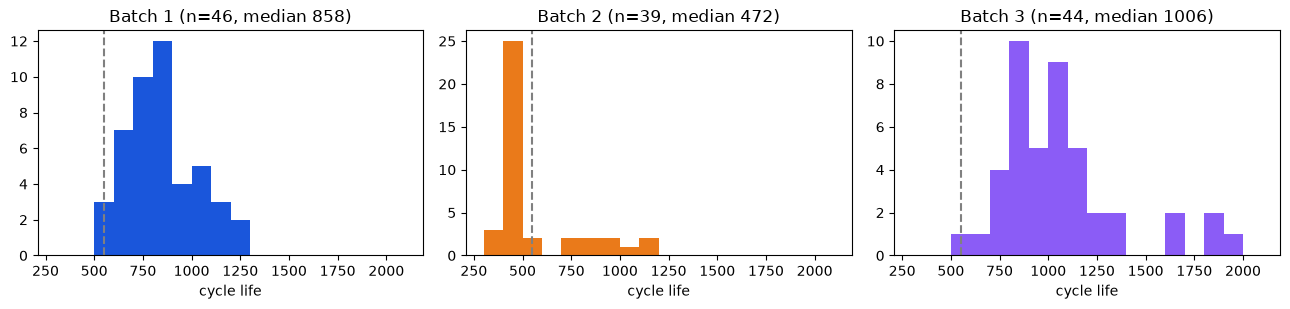

,count,min,median,max,<550,skew
batch,,,,,,
Batch 1,46,534.0,858.5,1227.0,1,0.453
Batch 2,39,392.0,472.0,1186.0,30,1.637
Batch 3,44,541.0,1005.5,1935.0,1,1.255


In [2]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2), sharex=True)
for ax, (b, g) in zip(axes, df.groupby("batch")):
    ax.hist(g.life, bins=np.arange(300, 2101, 100), color=COLORS[b])
    ax.axvline(550, color="gray", ls="--")
    ax.set(title=f"{b} (n={len(g)}, median {g.life.median():.0f})", xlabel="cycle life")
plt.tight_layout(); plt.show()
summary = df.groupby("batch").life.agg(["count", "min", "median", "max"])
summary["<550"] = df.groupby("batch").life.apply(lambda s: (s < 550).sum())
summary["skew"] = df.groupby("batch").life.skew()
summary

**확인.** 논문의 분류 기준인 550회 미만 셀이 학습 배치(Batch 1)에는 **1셀**뿐이다. 이 상태로는 분류기가 단수명 클래스를 학습할 수 없으므로 **회귀(cycle_life 예측)**로 간다.

**모델링에 주는 의미.** Batch 1의 수명 범위는 534~1,227회인데, Batch 2 중앙값은 472회로 이 범위 아래에 있다. 테스트 셀 상당수가 학습 범위 밖이므로 **범위 밖으로도 예측할 수 있는 모델**이 필요하다. 트리 모델은 학습 범위 밖 값을 내지 못한다는 점을 03의 후보 비교에서 확인한다.

## 2. Batch 2 실험 절차

In [3]:
b2 = df[df.batch == "Batch 2"]
display(b2.groupby("structure").life.agg(["count", "min", "median", "max"]))
display(df.groupby(["batch", "structure"]).size().unstack(fill_value=0))

,count,min,median,max
structure,,,,
newstructure,9,777.0,904.0,1186.0
original,30,392.0,451.0,514.0


structure,newstructure,original
batch,,
Batch 1,0,46
Batch 2,9,30
Batch 3,44,0


**확인.** Batch 2에는 기존 절차 30셀(392~514회)과 휴지 시간을 없앤 `newstructure` 9셀(777~1,186회)이 섞여 있다. 두 집단의 수명 범위는 겹치지 않는다. Batch 3은 44셀 전부 `newstructure`다.

**모델링에 주는 의미.** Batch 2 성능은 전체와 함께 **절차별**로도 나눠 본다. 배치 간 차이에는 시기 차이와 절차 차이가 섞여 있다.

## 3. 열화 곡선과 Knee point

100회 이후 용량 곡선을 두 직선으로 근사해 잔차가 가장 작아지는 지점을 Knee로 본다. 이 값은 수명이 끝난 뒤에야 알 수 있으므로 **EDA 전용**이다.

,cells,knee_median,accelerates_2x
batch,,,
Batch 1,46,645.0,42
Batch 2,39,360.0,39
Batch 3,44,810.0,43


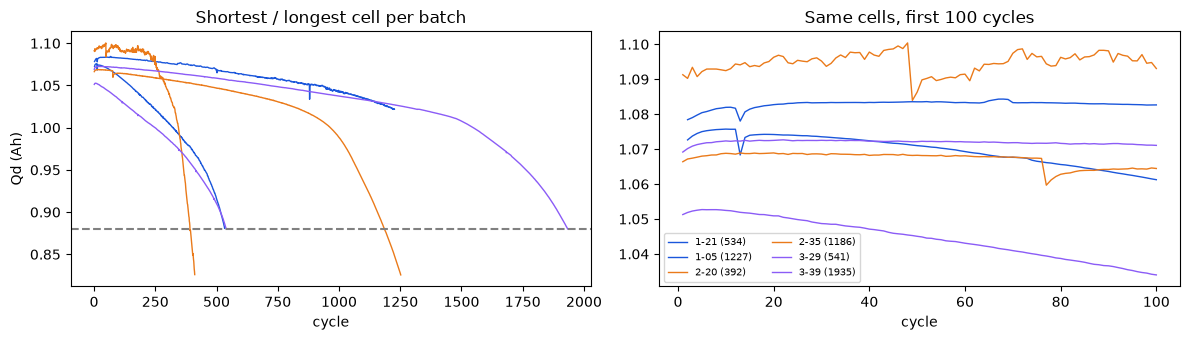

In [4]:
cap = pd.read_csv("../data/processed/capacity.csv.gz").merge(df[["cell", "batch", "life"]], on="cell")
cap = cap[(cap.qd > 0.5) & (cap.qd < 1.5)]  # 1회차 더미(0)와 측정 스파이크는 그림·Knee 계산에서만 뺀다

def knee(g):
    g = g[(g.cycle >= 100) & (g.cycle <= g.life.iloc[0])].iloc[::10]
    x, y = g.cycle.to_numpy(), g.qd.to_numpy()
    best = None
    for cut in range(max(5, len(x) // 5), min(len(x) - 5, len(x) * 4 // 5)):
        l, r = np.polyfit(x[:cut], y[:cut], 1), np.polyfit(x[cut:], y[cut:], 1)
        err = ((y[:cut] - np.polyval(l, x[:cut]))**2).sum() + ((y[cut:] - np.polyval(r, x[cut:]))**2).sum()
        if best is None or err < best[0]:
            best = (err, x[cut], l[0], r[0])
    return pd.Series({"knee": best[1], "slope_ratio": best[3] / best[2]})

knees = cap.groupby(["batch", "cell"]).apply(knee, include_groups=False).reset_index()
display(knees.groupby("batch").agg(cells=("cell", "size"), knee_median=("knee", "median"),
                                   accelerates_2x=("slope_ratio", lambda s: (s > 2).sum())))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for b, g in df.groupby("batch"):
    for _, row in g.iloc[[g.life.argmin(), g.life.argmax()]].iterrows():
        t = cap[cap.cell == row.cell]
        axes[0].plot(t.cycle, t.qd, color=COLORS[b], lw=1)
        axes[1].plot(t.cycle[t.cycle <= 100], t.qd[t.cycle <= 100], color=COLORS[b], lw=1, label=f"{row.cell} ({row.life:.0f})")
axes[0].axhline(0.88, color="gray", ls="--"); axes[0].set(title="Shortest / longest cell per batch", xlabel="cycle", ylabel="Qd (Ah)")
axes[1].set(title="Same cells, first 100 cycles", xlabel="cycle"); axes[1].legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.show()

**확인.** 대부분의 셀에서 후반 기울기가 초반보다 2배 이상 가팔라진다. Knee 중앙값은 Batch 2가 가장 이르고 Batch 3이 가장 늦다. 오른쪽 그림처럼 **100회까지는 수명이 짧은 셀과 긴 셀의 용량 곡선이 거의 구분되지 않는다.**

**모델링에 주는 의미.** Knee와 101회 이후 값은 예측 시점에 알 수 없으므로 입력에서 제외한다. 용량 **값**이 아니라 같은 100회 안에서 방전 곡선 **형태**가 어떻게 변했는지를 봐야 한다.

## 4. ΔQ(V) 곡선

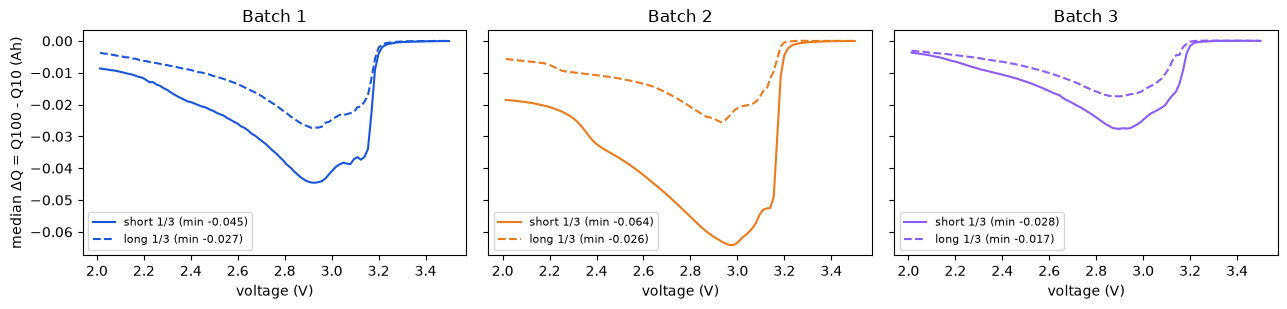

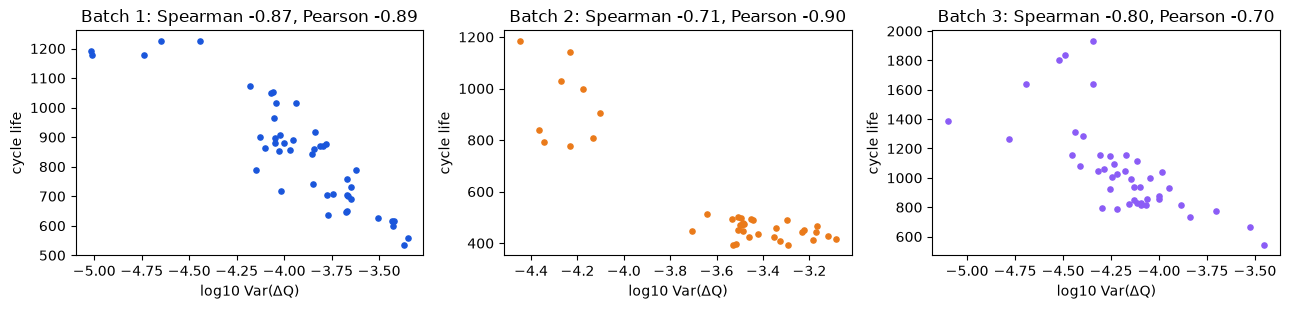

In [5]:
qv = pd.read_csv("../data/processed/qv_curves.csv.gz").merge(df[["cell", "batch", "life"]], on="cell")
qv["dq"] = qv.q100 - qv.q10
qv["group"] = qv.groupby("batch").life.transform(lambda s: pd.qcut(s, 3, labels=["short", "mid", "long"]))
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2), sharey=True)
for ax, (b, g) in zip(axes, qv.groupby("batch")):
    for grp, ls in (("short", "-"), ("long", "--")):
        m = g[g.group == grp].groupby("voltage").dq.median()
        ax.plot(m.index, m.values, ls, color=COLORS[b], label=f"{grp} 1/3 (min {m.min():.3f})")
    ax.set(title=b, xlabel="voltage (V)"); ax.legend(fontsize=8)
axes[0].set_ylabel("median ΔQ = Q100 - Q10 (Ah)")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
for ax, (b, g) in zip(axes, df.groupby("batch")):
    ax.scatter(g.dq_log_var, g.life, s=14, color=COLORS[b])
    ax.set(title=f"{b}: Spearman {spearmanr(g.dq_log_var, g.life)[0]:.2f}, Pearson {np.corrcoef(g.dq_log_var, g.life)[0, 1]:.2f}",
           xlabel="log10 Var(ΔQ)", ylabel="cycle life")
plt.tight_layout(); plt.show()

**확인.** 세 배치 모두 수명 하위 1/3의 ΔQ 곡선이 상위 1/3보다 깊다. 셀별 ΔQ 로그분산과 수명의 순위상관은 Batch 1에서 −0.87, Batch 2·3에서도 −0.71, −0.80으로 부호와 크기가 유지된다. Batch 1에서 Pearson이 −0.89로 Spearman과 거의 같아, 관계가 **거의 직선**이다.

**모델링에 주는 의미.** ΔQ 로그분산을 첫 피처로 두고 **선형 모델(Ridge)**부터 시작한다.

### ΔQ는 무엇을 재는가

방전하면 전압이 3.5V에서 2.0V로 내려가는 동안 전기가 빠져나온다. 전압마다 "여기까지 몇 Ah가 나왔나"를 적은 것이 방전 곡선 Q(V)다(원본의 Qdlin, 1,000개 전압 지점).

- **ΔQ(V) = Q100(V) − Q10(V)** : 10회차와 100회차 방전 곡선을 **같은 전압끼리** 뺀 값이다. 90사이클 동안 전압 구간마다 나온 전기량이 얼마나 바뀌었는지를 보여준다.
- **ΔQ 로그분산** : 그 변화가 전압 구간마다 얼마나 고르지 않은지를 분산으로 재고 log10을 씌운 값이다. 클수록(0에 가까울수록) 곡선 모양이 많이 변했다는 뜻이다.

같은 Batch 1에서 수명 라벨이 정확한(0.88Ah 도달까지 기록된) 셀 중 가장 짧은 셀과 가장 긴 셀을 비교한다.

,policy,life,Qd 10회 (Ah),Qd 100회 (Ah),ΔQ 최솟값 (Ah),ΔQ 로그분산
cell,,,,,,
1-21,5.4C(80%)-5.4C,534.0,1.076,1.061,-0.064,-3.367
1-06,4.4C(80%)-4.4C,1074.0,1.080,1.080,-0.025,-4.179


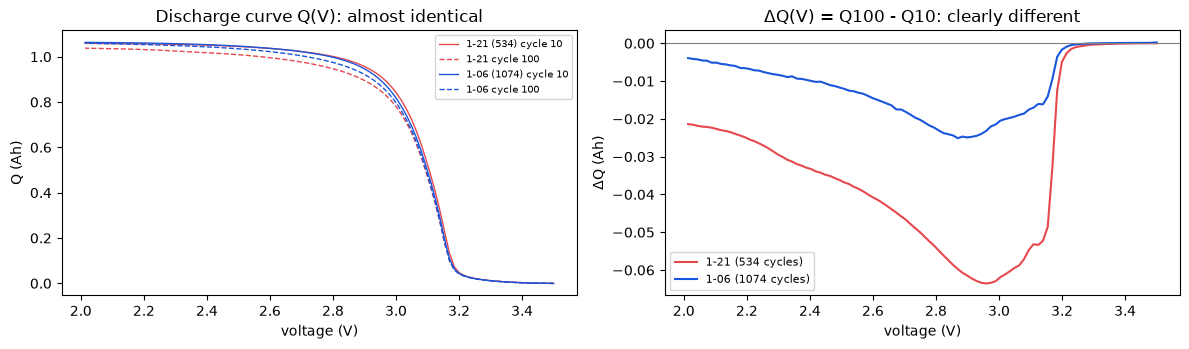

In [6]:
last_qd = cap.groupby("cell").qd.last()
b1_all = df[df.batch == "Batch 1"]
complete = b1_all[b1_all.cell.map(last_qd) < 0.885]  # 0.88Ah 도달까지 기록된 셀
pair = complete.loc[[complete.life.idxmin(), complete.life.idxmax()]]
raw_cap = pd.read_csv("../data/processed/capacity.csv.gz").set_index(["cell", "cycle"]).qd
display(pd.DataFrame({
    "policy": pair.policy.values, "life": pair.life.values,
    "Qd 10회 (Ah)": [raw_cap[c, 10] for c in pair.cell], "Qd 100회 (Ah)": [raw_cap[c, 100] for c in pair.cell],
    "ΔQ 최솟값 (Ah)": pair.dq_min.values, "ΔQ 로그분산": pair.dq_log_var.values}, index=pair.cell).round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for (cell, life), color in zip(pair[["cell", "life"]].values, ("#E5484D", "#1A56DB")):
    g = qv[qv.cell == cell]
    axes[0].plot(g.voltage, g.q10, color=color, lw=1, label=f"{cell} ({life:.0f}) cycle 10")
    axes[0].plot(g.voltage, g.q100, color=color, lw=1, ls="--", label=f"{cell} cycle 100")
    axes[1].plot(g.voltage, g.dq, color=color, label=f"{cell} ({life:.0f} cycles)")
axes[0].set(title="Discharge curve Q(V): almost identical", xlabel="voltage (V)", ylabel="Q (Ah)"); axes[0].legend(fontsize=7)
axes[1].axhline(0, color="gray", lw=.8)
axes[1].set(title="ΔQ(V) = Q100 - Q10: clearly different", xlabel="voltage (V)", ylabel="ΔQ (Ah)"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

**확인.**
- 수명은 534회와 1,074회로 2배 차이지만, 100회차 방전 용량은 1.061Ah와 1.080Ah로 2%도 차이 나지 않는다. 둘 다 수명 기준(0.88Ah)까지 아직 한참 남았다. 왼쪽 그림처럼 방전 곡선도 거의 겹친다. **100회 시점의 용량만으로는 어느 셀이 먼저 망가질지 알기 어렵다.**
- 같은 전압끼리 빼면(오른쪽) 차이가 드러난다. 단수명 셀은 2.9~3.0V 근처에서 최대 −0.064Ah까지 꺼지고, 장수명 셀은 −0.025Ah에 그친다. 곡선이 꺼진 깊이와 고르지 않은 정도를 담은 ΔQ 로그분산도 −3.37 vs −4.18로 뚜렷하게 갈린다.

**도메인 해석.** 셀 내부가 상하기 시작하면(전극 표면 피막 성장, 쓸 수 있는 리튬 감소, 활물질 손실 등) 총 용량이 줄기 **전에** 특정 전압 구간에서 먼저 곡선이 변형된다. 총량은 그대로여도 구간별 변화가 고르지 않게 나타난다. ΔQ 로그분산은 이 초기 변형을 숫자 하나로 잡는 조기 경보다. 그래서 용량이 아직 멀쩡한 100회 시점에 이미 수명 차이를 읽을 수 있다.

## 5. 충전 조건

In [7]:
rows = []
for b, g in df.groupby("batch"):
    rows.append({"batch": b,
                 "C-rate vs life": spearmanr(g.first_c_rate, g.life)[0],
                 "current P90 vs life": spearmanr(g.charge_current_p90_c10, g.life)[0],
                 "current P90 vs ΔQ": spearmanr(g.charge_current_p90_c10, g.dq_log_var)[0],
                 "current P90 vs C-rate": spearmanr(g.charge_current_p90_c10, g.first_c_rate)[0]})
display(pd.DataFrame(rows).set_index("batch"))
policy = df[df.batch == "Batch 1"].groupby("policy").life.agg(["count", "mean"]).sort_values("mean")
display(pd.concat([policy.head(3), policy.tail(3)]))

,C-rate vs life,current P90 vs life,current P90 vs ΔQ,current P90 vs C-rate
batch,,,,
Batch 1,-0.483,-0.511,0.558,0.974
Batch 2,0.055,-0.301,0.395,0.451
Batch 3,-0.229,-0.565,0.689,0.640


,count,mean
policy,,
5.4C(80%)-5.4C,2,546.5
8C(35%)-3.6C,2,607.5
7C(40%)-3.6C,2,621.0
4.4C(80%)-4.4C,1,1074.0
3.6C(80%)-3.6C,3,1182.0
4C(80%)-4C,2,1226.5


**확인.** Batch 1에서 첫 C-rate와 수명의 순위상관은 −0.48이지만, Batch 2에서는 +0.06, Batch 3에서는 −0.23으로 배치마다 흔들린다. 충전 전류 P90과 첫 C-rate의 상관은 Batch 1에서 0.97로 사실상 같은 값이지만, Batch 2는 0.45, Batch 3은 0.64로 떨어진다. 같은 정책 문자열이어도 배치마다 실제 측정된 전류 패턴이 다르다는 뜻이다(7절의 충전 시작 상태 차이와 연결된다). 정책별 평균 수명은 546~1,226회로 2배 이상 차이 나지만 정책당 셀이 1~3개뿐이다.

**모델링에 주는 의미.** 충전 조건은 ΔQ에 더해 볼 **보조 후보**로 두고, 전류와 C-rate는 따로 비교한다. Batch 1 안에서 같은 정보라면 두 피처의 CV 결과도 같아야 한다. 이 점은 02에서 확인한다. 충전 기반 피처는 배치가 바뀌면 의미가 달라질 수 있다는 점도 함께 기억해 둔다.

## 6. 피처 간 상관

In [8]:
feats = ["dq_log_var", "qd_delta_100_10", "IR_early", "Tavg_early", "Tmax_early", "chargetime_early", "first_c_rate", "charge_current_p90_c10"]
display(df.groupby("batch").apply(lambda g: g[feats].corrwith(g.life, method="spearman"), include_groups=False).T)
b1 = df[df.batch == "Batch 1"]
print("Batch 1 평균온도-최고온도 ρ:", round(spearmanr(b1.Tavg_early, b1.Tmax_early)[0], 2))
print("Batch 1 ΔQ 로그분산-ΔQ 최솟값 ρ:", round(spearmanr(b1.dq_log_var, b1.dq_min)[0], 2))

batch,Batch 1,Batch 2,Batch 3
dq_log_var,-0.871,-0.709,-0.797
qd_delta_100_10,0.613,-0.055,0.032
IR_early,0.281,-0.344,0.171
Tavg_early,-0.380,0.172,0.023
Tmax_early,-0.321,-0.140,-0.049
chargetime_early,0.638,-0.809,0.264
first_c_rate,-0.483,0.055,-0.229
charge_current_p90_c10,-0.511,-0.301,-0.565


Batch 1 평균온도-최고온도 ρ: 0.96
Batch 1 ΔQ 로그분산-ΔQ 최솟값 ρ: -0.99


**확인.** 세 배치에서 부호와 크기가 모두 유지되는 것은 ΔQ 로그분산뿐이다. 초기 용량 변화는 +0.61 → −0.06 → +0.03, 충전시간은 +0.64 → −0.81로 배치에 따라 신호가 사라지거나 부호가 뒤집힌다. 평균·최고온도(0.96)와 ΔQ 분산·최솟값(−0.99)은 서로 겹친다.

**모델링에 주는 의미.** ΔQ를 중심에 두고, 겹치는 쌍은 하나만 후보로 둔다(평균온도, ΔQ 로그분산). ΔQ에 충전 전류, 온도·저항, 초기 용량 변화를 하나씩 더해 보며 확인한다. Batch 1 상관이 Batch 2·3에서 유지되지 않는 피처는 CV에서 이득을 보이더라도 배치 이동에 취약할 수 있다.

## 7. 배치 간 Qdlin 비교

과제는 배치마다 충전 커브의 시작 시점이 달라 Qdlin을 단순 비교하면 왜곡될 수 있다고 짚었다. 원본에서 배치별 10회차 기록의 시작 상태와 곡선 높이를 먼저 비교한다.

In [9]:
display(df.groupby("batch")[["first_cycle_qd", "charge_start_v_c10", "charge_start_i_c10", "q10_at_3v"]].agg(["min", "median", "max"])
        .rename(columns={"first_cycle_qd": "1회차 Qd (Ah)", "charge_start_v_c10": "10회차 시작 V",
                         "charge_start_i_c10": "10회차 시작 I (A)", "q10_at_3v": "Q10 at 3.0V (Ah)"}))

1회차 Qd (Ah)               10회차 시작 V               10회차 시작 I (A)  \
                min median    max       min median    max           min   
batch                                                                     
Batch 1       0.000  0.000  0.000     2.016  2.021  2.029         0.000   
Batch 2       1.066  1.096  1.108     2.119  2.348  2.373         0.247   
Batch 3       1.045  1.064  1.073     2.078  2.104  2.134         0.254   

                     Q10 at 3.0V (Ah)                
        median   max              min median    max  
batch                                                
Batch 1  0.000  0.00            0.798  0.843  0.869  
Batch 2  0.384  0.57            0.807  0.853  0.899  
Batch 3  0.397  0.61            0.810  0.849  0.884

배치 간 차이는 세 가지다.

- **1회차 기록.** Batch 1은 46셀 전부 1회차 방전 용량이 0Ah인 빈 기록이다. Batch 2·3은 1.05~1.11Ah로 실제 측정값이다.
- **충전 시작 상태.** 10회차 기록이 시작되는 전압·전류가 다르다(중앙값 2.02V·0A / 2.35V·0.38A / 2.10V·0.40A). 기록이 충전 과정의 다른 지점에서 시작된다는 뜻이다.
- **곡선 높이.** 같은 3.0V에서의 10회차 방전 용량 Q10도 배치마다 다르다.

### 7-1. 곡선 높이와 충전 시작 상태

ΔQ(V) = Q100(V) − Q10(V)는 **같은 셀**의 두 방전 곡선을 **같은 전압 격자**(3.5→2.0V, 1,000점)에서 뺀 값이다. 셀·배치마다 곡선 높이가 달라도 그 차이는 뺄셈에서 상쇄된다. 또 Qdlin은 방전 구간을 전압 기준으로 보간한 곡선이라, 충전 구간의 시작 상태와는 무관하다. 문제가 되는 건 충전 구간을 직접 쓰는 피처(충전 전류 P90 등)다.

### 7-2. 사이클 번호 어긋남

남는 위험은 사이클 번호다. Batch 1의 1회차가 실제 방전이 없는 빈 기록이라면, Batch 1에서 "10회차·100회차"로 적힌 기록은 실제로는 9번째·99번째 방전일 수 있다. 그러면 같은 번호로 ΔQ를 계산해도 Batch 1과 Batch 2·3은 **한 사이클 어긋난 지점끼리** 비교하게 된다.

이 어긋남이 결과를 바꾸는지 다음 순서로 확인한다.
1. 모든 셀에서 사이클 번호가 1부터 빠짐없이 이어지는지 확인한다. 번호로 사이클을 찾는 방식이 맞는지 보기 위해서다.
2. 원본에서 사이클 번호 11·101의 곡선을 직접 찾아 한 사이클 밀린 ΔQ(Q101 − Q11)를 계산한다(`src/preprocess.py`). 어긋남이 있었다면 이 값이 그것을 바로잡은 값이 된다.
3. 원래 ΔQ와 비교한다. 피처 값의 변화와 수명과의 순위상관 변화를 보고, 배치 간 차이와도 견준다.

In [10]:
print("사이클 번호가 1부터 빠짐없이 이어지는 셀:", df.cycle_contiguous.sum(), "/", len(df))
change = df.dq_log_var_c11_c101 - df.dq_log_var
rows = []
for b, g in df.assign(change=change).groupby("batch"):
    rows.append({"batch": b, "cells": len(g),
                 "평균 변화": g.change.mean(), "셀별 최대 |변화|": g.change.abs().max(),
                 "ρ 원래 (Q100−Q10)": spearmanr(g.dq_log_var, g.life)[0],
                 "ρ 이동 (Q101−Q11)": spearmanr(g.dq_log_var_c11_c101, g.life)[0]})
display(pd.DataFrame(rows).set_index("batch"))
gap = df[df.batch == "Batch 2"].dq_log_var.median() - b1.dq_log_var.median()
print(f"비교 기준 - 배치 간 ΔQ 로그분산 중앙값 차이(Batch 2 − Batch 1): {gap:.3f}")

사이클 번호가 1부터 빠짐없이 이어지는 셀: 129 / 129


,cells,평균 변화,셀별 최대 |변화|,ρ 원래 (Q100−Q10),ρ 이동 (Q101−Q11)
batch,,,,,
Batch 1,46,0.003,0.215,-0.871,-0.853
Batch 2,39,0.003,0.352,-0.709,-0.716
Batch 3,44,0.018,0.324,-0.797,-0.800


비교 기준 - 배치 간 ΔQ 로그분산 중앙값 차이(Batch 2 − Batch 1): 0.364


**확인.**
- 129셀 모두 사이클 번호가 1부터 빠짐없이 이어진다. 번호로 10·11·100·101회차를 찾는 방식에 문제가 없다.
- 한 사이클을 밀어도 ΔQ 로그분산의 배치 평균 변화는 0.003 / 0.003 / 0.018에 그친다. 수명과의 순위상관도 −0.871 → −0.853, −0.709 → −0.716, −0.797 → −0.800으로 거의 그대로다. 초기 100회 동안 방전 곡선이 아주 천천히 변하기 때문이다.
- 배치 간 중앙값 차이(0.364)는 평균 변화보다 약 20배 크다. Batch 1의 1회차가 빈 기록이든 아니든, **사이클 번호 어긋남으로는 배치 간 차이를 설명할 수 없다.**
- 다만 셀 하나만 보면 최대 0.2~0.35까지 움직인다. 배치 수준의 결론은 바뀌지 않지만, 개별 셀의 예측값은 한 사이클 차이로도 흔들릴 수 있다.

**모델링에 주는 의미.**
- 피처는 Qdlin 원본 곡선이 아니라 **같은 셀 안의 차이인 ΔQ**로 만든다. 10·100회차는 사이클 번호로 찾고, 별도 보정은 하지 않는다.
- 측정 기록 문제로 배치 차이가 생긴 것이 아니므로, Batch 2의 ΔQ 분포가 다른 것은 **셀 자체의 차이**로 보고 03의 오차 분석에서 다시 확인한다.
- 충전 구간은 시작 상태가 배치마다 달라, 충전 전류 P90과 C-rate의 관계도 Batch 1(0.97)과 Batch 2(0.45)에서 크게 다르다. 충전 기반 피처는 배치 이동에 취약한 후보로 본다.

## 정리

- **문제는 "누가 오래 사나"보다 "어느 배치에서 왔나"가 더 큼**
  - 수명 중앙값이 858 / 472 / 1,006회로 배치마다 다르고, Batch 2는 대부분 학습 범위 아래에 있음
  - 학습 배치에 550회 미만 셀이 1개뿐이라 분류는 처음부터 불가능 → 회귀
  - 테스트 셀 상당수가 학습 범위 밖이므로 범위 밖으로 예측할 수 있는 모델이어야 함 → 트리보다 선형 모델
- **100회 시점의 용량 값 자체에는 답이 없음**
  - 장수명·단수명 셀의 용량 곡선이 100회까지 거의 겹치고, 꺾임(Knee)은 수명 후반에야 나타남
  - 그래서 용량이 "얼마나 남았나"가 아니라 방전 곡선 모양이 "어떻게 변했나"를 봐야 함
- **ΔQ 로그분산이 유일하게 배치를 넘어 살아남는 신호**
  - 다른 후보들은 Batch 1에서만 상관이 보이고, 다른 배치에서는 사라지거나 부호가 뒤집힘
  - ΔQ만 세 배치에서 −0.71~−0.87을 유지함. Batch 1에서는 거의 직선이라 Ridge 한 줄로 시작하면 됨
  - 이후 피처를 더할 때는 "Batch 1 CV에서 실제로 줄어드는가"만 기준으로 삼음
- **충전 조건은 직관과 달리 조심해야 할 피처**
  - 고속 충전일수록 수명이 짧다는 경향은 Batch 1에서만 뚜렷함
  - 전류와 C-rate는 Batch 1에서 같은 값(0.97)인데 다른 배치에서는 어긋남(0.45·0.64). 정책 문자열이 같아도 측정된 충전 과정이 배치마다 다르다는 뜻
  - 충전 정보는 ΔQ에 이미 반영됐을 가능성이 큼(전류-ΔQ 0.56) → 02에서 더했을 때 이득이 있는지 확인
- **Qdlin 시작점 문제는 ΔQ 정의 자체가 막아 줌**
  - 1회차 빈 기록(Batch 1), 충전 시작 상태, 곡선 높이가 배치마다 달라 원본 곡선을 배치끼리 직접 비교하면 왜곡됨
  - 같은 셀의 10·100회차 차이를 쓰면 높이 차이가 상쇄됨. 원본에서 한 사이클 밀어 다시 계산해도 배치 평균 변화는 0.02 이하라 번호 어긋남도 문제가 되지 않음
  - 그런데도 Batch 2의 ΔQ 분포는 Batch 1과 꽤 다름(중앙값 차이 0.36) → 배치 이동은 측정 방식이 아니라 셀 자체의 차이일 가능성. 03에서 Batch 2 오차를 해석할 때 다시 확인할 지점

→ **02에서 할 일:** ΔQ 하나로 시작해 충전 전류, 온도·저항, 초기 용량 변화를 하나씩 더해 보고, Batch 1 CV가 실제로 줄어드는 것만 남긴다.